# RAII and class invariants

Follow a feature that shapes how this language is used in practice.

Work with a small fixture so that every returned value can be checked by hand. Keep the ordering of inputs visible. Trace resource ownership, data shape or scheduling as appropriate, and identify the exact point where the result becomes available to the caller.

A deque and its running total are owned by a class. The constructor enforces a positive width and value checks that the window is complete.

In [1]:
from pathlib import Path
import sys, math, statistics
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd()
sys.path.insert(0, str(here.parent.parent))
from course_runner import run_native

## Native source

`native.cpp`

```cpp
#include <iostream>
#include <iomanip>
#include <deque>
#include <stdexcept>
#include <vector>

class RollingMean {
    std::deque<double> data;
    std::size_t width;
    double total = 0;
public:
    explicit RollingMean(std::size_t n) : width(n) {
        if (!n) throw std::invalid_argument("zero width");
    }
    void push(double value) {
        data.push_back(value);
        total += value;
        if (data.size() > width) { total -= data.front(); data.pop_front(); }
    }
    bool full() const { return data.size() == width; }
    double value() const {
        if (!full()) throw std::logic_error("incomplete window");
        return total / width;
    }
};

int main() {
    std::cout << std::setprecision(12);
    RollingMean mean(3);
    for (int value : {2, 4, 8, 1, 3, 7}) {
        mean.push(value);
        if (mean.full()) std::cout << mean.value() << ' ';
    }
}
```

## Execute the native listing

A deque and its running total are owned by a class. The constructor enforces a positive width and value checks that the window is complete. Look at the lifetime of each object and the owner of its storage. Passing a const reference permits observation without copying the container. Algorithms operate on half-open iterator ranges.

In [2]:
x = [2, 4, 8, 1, 3, 7]
expected = np.asarray([sum(x[i : i + 3]) / 3 for i in range(len(x) - 2)], dtype=float)
engine, stdout = run_native(here / "native.cpp")
observed = np.asarray([float(v) for v in stdout.split()])
assert observed.shape == expected.shape
np.testing.assert_allclose(observed, expected, rtol=2e-7, atol=2e-7)
print("Runtime:", engine)
print("Native stdout:", stdout.strip())
print("Largest absolute difference:", f"{np.max(np.abs(observed-expected)):.3g}")

Runtime: C++
Native stdout: 4.66666666667 4.33333333333 4 3.66666666667
Largest absolute difference: 3.33e-12


## Read the output

The independent calculation describes the expected output. Its agreement with the native result tests both the values and their order. The marks show the independent Python reference at each position.

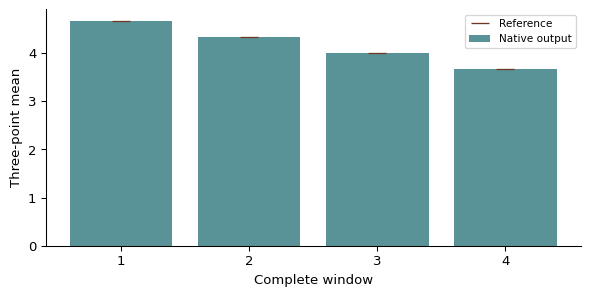

In [3]:
labels = [str(v) for v in range(1, 5)]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.1, 3), constrained_layout=True)
ax.bar(positions, observed, color="#367b80", alpha=0.82, label="Native output")
ax.plot(
    positions,
    expected,
    linestyle="none",
    marker="_",
    markersize=13,
    color="#713925",
    label="Reference",
)
ax.set(xticks=positions, xticklabels=labels, xlabel="Complete window", ylabel="Three-point mean")
ax.legend(fontsize=8)
plt.show()

## Interpreting the result

The independent calculation describes the expected output. Its agreement with the native result tests both the values and their order.

## Exercise

Change the input length, add a repeated value and predict all output positions before running the programme.

## References

[C++ language and standard library reference](https://en.cppreference.com/w/cpp)